In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

In [2]:
df=pd.read_csv("Ice_cream selling data.csv")
df.head()

,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Temperature (°C)         49 non-null     float64
 1   Ice Cream Sales (units)  49 non-null     float64
dtypes: float64(2)
memory usage: 916.0 bytes


In [4]:
X=df[['Temperature (°C)']]       #2D
Y=df['Ice Cream Sales (units)']  #1D

In [5]:
xtrain,xtest,ytrain,ytest=train_test_split(X,Y,test_size=0.2,random_state=42)

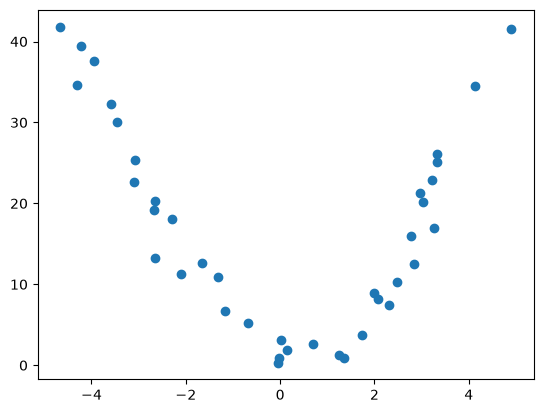

In [6]:
import matplotlib.pyplot as plt
plt.scatter(xtrain,ytrain)      # Non-linear pattern

In [7]:
poly=PolynomialFeatures(degree=3)

With the help of polynomial features we are going to transform xtrain and xtest with degree 2

here we use 2 methods

1) fit_transform() 

- it learns the patterns first the transform the values

    syntax:

    xtrain_poly=poly.fit_transform(xtrain)

    =>How fit_transform() works in polynomial regression?

    *fit()* : learns the pattern

    (decides how many features needs to be create based on degree)

    *transform()* : transform the values based on created features

    **Note:**
    After fit_transform() information stors inside poly(object)


2) transform()

- it transforms the values directly with the help of object --> poly(having information,how many features created)





In [8]:
xtrain_poly=poly.fit_transform(xtrain)
# xtrain should be having numeric values
print(xtrain_poly)

[[ 1.00000000e+00 -2.11186969e+00  4.45999359e+00 -9.41892528e+00]
 [ 1.00000000e+00 -3.57855372e+00  1.28060467e+01 -4.58271260e+01]
 [ 1.00000000e+00  2.31859124e+00  5.37586534e+00  1.24644343e+01]
 [ 1.00000000e+00 -2.67246083e+00  7.14204687e+00 -1.90868405e+01]
 [ 1.00000000e+00 -3.94966109e+00  1.55998227e+01 -6.16140128e+01]
 [ 1.00000000e+00 -3.10844012e+00  9.66239999e+00 -3.00349918e+01]
 [ 1.00000000e+00  3.21136614e+00  1.03128725e+01  3.31184096e+01]
 [ 1.00000000e+00  3.27004407e+00  1.06931882e+01  3.49671967e+01]
 [ 1.00000000e+00  4.13086796e+00  1.70640701e+01  7.04894205e+01]
 [ 1.00000000e+00 -1.32637898e+00  1.75928121e+00 -2.33347362e+00]
 [ 1.00000000e+00 -2.65228679e+00  7.03462523e+00 -1.86578436e+01]
 [ 1.00000000e+00 -1.17312327e+00  1.37621820e+00 -1.61447359e+00]
 [ 1.00000000e+00  6.88780908e-01  4.74419139e-01  3.26770845e-01]
 [ 1.00000000e+00  2.07510060e+00  4.30604249e+00  8.93547133e+00]
 [ 1.00000000e+00  1.74000001e+00  3.02760004e+00  5.26802411e

In [9]:
xtest_poly=poly.transform(xtest)
xtest_poly

array([[ 1.00000000e+00, -1.81893761e+00,  3.30853403e+00,
        -6.01801697e+00],
       [ 1.00000000e+00,  3.70405744e+00,  1.37200415e+01,
         5.08198218e+01],
       [ 1.00000000e+00,  4.13353379e+00,  1.70861016e+01,
         7.06259782e+01],
       [ 1.00000000e+00,  3.61077848e+00,  1.30377212e+01,
         4.70763232e+01],
       [ 1.00000000e+00, -7.73330043e-01,  5.98039356e-01,
        -4.62481801e-01],
       [ 1.00000000e+00,  1.02418081e+00,  1.04894634e+00,
         1.07431072e+00],
       [ 1.00000000e+00,  8.74905029e-01,  7.65458810e-01,
         6.69703763e-01],
       [ 1.00000000e+00,  6.93598873e-01,  4.81079396e-01,
         3.33676127e-01],
       [ 1.00000000e+00,  1.85055193e+00,  3.42454243e+00,
         6.33729359e+00],
       [ 1.00000000e+00, -1.49634867e-01,  2.23905933e-02,
        -3.35041344e-03]])

In [10]:
model=LinearRegression()

model.fit(xtrain_poly,ytrain)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 0. ,-1.4 , 1.88, 0.05]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.841
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[244.86, 38.67, 7.47, 0. ]"


score()  and  r2_score() both are same

model.score(x,y)

train r2_score(xtrain,ytrain)



In [11]:
train_r2score=model.score(xtrain_poly,ytrain)
test_r2score=model.score(xtest_poly,ytest)
print(f'''Train r2 score --> {train_r2score}\nTest r2 score --> {test_r2score}''')

Train r2 score --> 0.9469116778215552
Test r2 score --> 0.8405107685716915


### CONCLUSION:

**Train Data**
 - Linear Regression capture the non-linear data pattern with the help of polynomial features
 - Model captures '94%' of the seen data(train data) pattern,so it learns the pattern properly

**Test Data**
 - Linear Regression captures 84% of unseen data pattern,so it is ready for future predictions.
 - Model can perform well on unseen data(test data/new data for future prediction)

In [12]:
ytrain_predicted=model.predict(xtrain_poly)
ytest_predicted=model.predict(xtest_poly)

## Train score

Actual pattern vs Predicted pattern

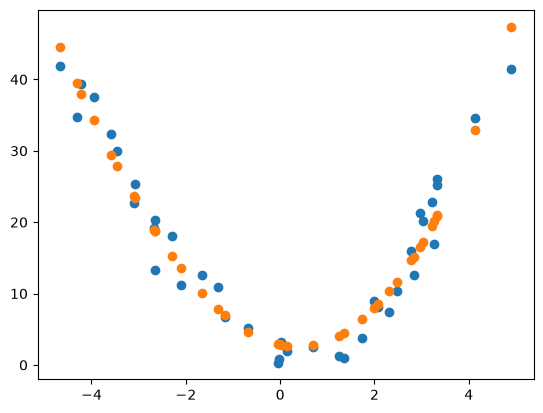

In [13]:
plt.scatter(xtrain,ytrain)
plt.scatter(xtrain,ytrain_predicted)

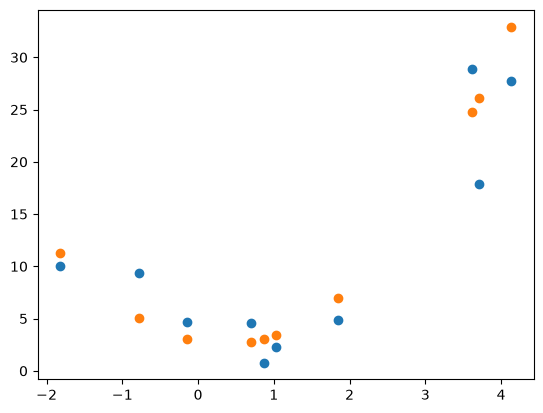

In [14]:
plt.scatter(xtest,ytest)
plt.scatter(xtest,ytest_predicted)